# Preparação dos dados para o treinamento

Este notebook só prepara os conjuntos de treino, validação e teste e os salva em `datasets/processed/`. Os modelos ficam em `model.ipynb`, que carrega esses arquivos.

In [1]:
class Config:
    RANDOM_STATE = 42
    MAX_RAM_GB = 10
    MAX_ZERO_FRACTION = 0.95
    MIN_MEAN_TPM = 1
    MIN_LOG_VARIANCE = 0.01
    TEST_SIZE = 0.10
    VAL_SIZE = 0.20
    STRATIFY_COLUMNS = ["AGE", "SEX"]
    MAJORITY_AGES = ["50-59", "60-69"]
    UNDERSAMPLING_REFERENCE_AGE = "40-49"
    GAP_REDUCTION = 0.5
    OVERSAMPLING_GROUPS = [{"AGE": "20-29"}, {"AGE": "30-39"}, {"AGE": "70-79", "SEX": 2}]
    OVERSAMPLING_FACTOR = 3
    JITTER_SCALE = 0.30

In [2]:
import resource

max_bytes = Config.MAX_RAM_GB * 1024**3
resource.setrlimit(resource.RLIMIT_AS, (max_bytes, max_bytes))

import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from src.data.loader import load_all_regions, load_phenotypes, save_split

## Limpeza dos fenótipos

In [3]:
df = load_phenotypes()
regions = load_all_regions(nrows=None)

sample_region = {sample: region.value for region, expr in regions.items() for sample in expr.columns[2:]}
brain_donors = {"-".join(sample.split("-")[:2]) for sample in sample_region}

print("Doadores no arquivo de fenótipos:", len(df))
print("Linhas sem DTHHRDY:", df["DTHHRDY"].isna().sum())
print("K-562 presente:", (df["SUBJID"] == "K-562").any())

Doadores no arquivo de fenótipos: 981
Linhas sem DTHHRDY: 19
K-562 presente: True


In [4]:
phenotypes = df[df["SUBJID"].isin(brain_donors)].copy()

age_order = sorted(phenotypes["AGE"].unique())
phenotypes["AGE_ORD"] = phenotypes["AGE"].map({age: i + 1 for i, age in enumerate(age_order)})
phenotypes["DTHHRDY"] = phenotypes["DTHHRDY"].astype(int)

print("Doadores do cérebro:", len(phenotypes))
print("Linhas sem DTHHRDY:", phenotypes["DTHHRDY"].isna().sum())
print("K-562 presente:", (phenotypes["SUBJID"] == "K-562").any())
print("Codificação da idade:", dict(zip(age_order, range(1, len(age_order) + 1))))

Doadores do cérebro: 393
Linhas sem DTHHRDY: 0
K-562 presente: False
Codificação da idade: {'20-29': 1, '30-39': 2, '40-49': 3, '50-59': 4, '60-69': 5, '70-79': 6}


### Valores vazios de DTHHRDY e a linha K-562

No arquivo completo de fenótipos, 19 das 981 linhas (cerca de 1,94%) não têm DTHHRDY. Dessas, 18 são doadores reais sem o tipo de morte registrado, com idades e sexos variados, e uma é a K-562, uma linhagem celular de leucemia que o GTEx usa como controle técnico e que não representa uma pessoa. Nenhuma dessas linhas é uma soma ou total de outros grupos.

Ao manter apenas os 393 doadores que têm amostras de tecido cerebral, nenhum valor de DTHHRDY fica vazio (0%) e a K-562 sai junto, porque nenhum desses casos tem amostra de cérebro.

Distribuição de DTHHRDY entre os doadores do cérebro: 0 (ventilador) com 19, 1 (morte violenta e rápida) com 23, 2 (morte natural rápida) com 210, 3 (morte intermediária) com 40 e 4 (morte lenta) com 101. Chama atenção que o grupo 0 é o maior no arquivo completo (511 doadores), mas um dos menores entre os doadores do cérebro.

## Matriz de expressão (amostras x genes)

In [5]:
expression = pd.concat([expr.set_index("Name").drop(columns="Description").astype("float32") for expr in regions.values()], axis=1).T
gene_symbols = regions[next(iter(regions))].set_index("Name")["Description"]
del regions

samples = pd.DataFrame({"region": expression.index.map(sample_region)}, index=expression.index)
samples["SUBJID"] = samples.index.str.split("-").str[:2].str.join("-")
samples = samples.join(phenotypes.set_index("SUBJID")[["SEX", "AGE", "AGE_ORD", "DTHHRDY"]], on="SUBJID")

print(expression.shape)
samples.head()

(3234, 74628)


,region,SUBJID,SEX,AGE,AGE_ORD,DTHHRDY
GTEX-1117F-0011-R4b-SM-GI4VM,amygdala,GTEX-1117F,2,60-69,5,4
GTEX-111FC-0011-R4a-SM-GIN8K,amygdala,GTEX-111FC,1,60-69,5,1
GTEX-117XS-0011-R4b-SM-GJ3PR,amygdala,GTEX-117XS,1,60-69,5,2
GTEX-11DXY-0011-R4b-SM-GI4VR,amygdala,GTEX-11DXY,1,60-69,5,2
GTEX-11DYG-0011-R4b-SM-GJ3RG,amygdala,GTEX-11DYG,1,60-69,5,2


## Divisão em treino, validação e teste (70/20/10)

In [6]:
from sklearn.model_selection import train_test_split

strata = phenotypes[Config.STRATIFY_COLUMNS].astype(str).agg("_".join, axis=1)

donors_trainval, donors_test = train_test_split(
    phenotypes["SUBJID"], test_size=Config.TEST_SIZE, stratify=strata, random_state=Config.RANDOM_STATE
)
donors_train, donors_val = train_test_split(
    donors_trainval, test_size=Config.VAL_SIZE / (1 - Config.TEST_SIZE), stratify=strata.loc[donors_trainval.index], random_state=Config.RANDOM_STATE
)

samples["split"] = samples["SUBJID"].map(
    {**dict.fromkeys(donors_train, "train"), **dict.fromkeys(donors_val, "val"), **dict.fromkeys(donors_test, "test")}
)

donor_split = phenotypes.set_index("SUBJID").assign(split=samples.groupby("SUBJID")["split"].first())

display(pd.DataFrame({
    "Doadores": donor_split["split"].value_counts(),
    "Amostras": samples["split"].value_counts(),
}).loc[["train", "val", "test"]].assign(**{"% doadores": lambda t: (t["Doadores"] / t["Doadores"].sum() * 100).round(1)}))

display(pd.crosstab(donor_split["AGE"], donor_split["split"], normalize="columns").mul(100).round(1)[["train", "val", "test"]])
display(pd.crosstab(donor_split["SEX"], donor_split["split"], normalize="columns").mul(100).round(1)[["train", "val", "test"]])

,Doadores,Amostras,% doadores
split,,,
train,274,2261,69.7
val,79,658,20.1
test,40,315,10.2


split,train,val,test
AGE,,,
20-29,2.2,2.5,2.5
30-39,2.2,2.5,2.5
40-49,9.5,8.9,7.5
50-59,30.3,30.4,30.0
60-69,50.4,50.6,52.5
70-79,5.5,5.1,5.0


split,train,val,test
SEX,,,
1,71.5,70.9,75.0
2,28.5,29.1,25.0


## Filtro de genes (calculado só no treino)

In [7]:
train = samples["split"] == "train"
train_expression = expression[train]
n_genes = expression.shape[1]

zero_fraction = (train_expression == 0).mean()
keep = zero_fraction < Config.MAX_ZERO_FRACTION
after_zeros = keep.sum()

keep &= train_expression.mean() >= Config.MIN_MEAN_TPM
after_mean = keep.sum()

keep &= ~(train_expression.groupby(samples.loc[train, "region"]).std() == 0).any()

expression = expression.loc[:, keep]
del train_expression

pd.Series({
    "Genes iniciais": n_genes,
    "Zerados em todas as amostras de treino": (zero_fraction == 1).sum(),
    f"Após remover genes zerados em >= {Config.MAX_ZERO_FRACTION:.0%} das amostras": after_zeros,
    f"Após média de TPM >= {Config.MIN_MEAN_TPM}": after_mean,
    "Após remover variância zero em alguma região": expression.shape[1],
})

Genes iniciais                                       74628
Zerados em todas as amostras de treino                1389
Após remover genes zerados em >= 95% das amostras    56444
Após média de TPM >= 1                               17500
Após remover variância zero em alguma região         17500
dtype: int64

## Transformação log2(TPM + 1)

In [8]:
skew_before = expression[train].skew()
expression = np.log2(expression + 1)
skew_after = expression[train].skew()

pd.DataFrame({"antes": skew_before.describe(), "depois": skew_after.describe()})

,antes,depois
count,17500.000000,17500.000000
mean,2.329982,0.257763
std,2.822651,0.686775
min,-0.164226,-5.666142
25%,1.151054,-0.258825
50%,1.744851,0.195240
75%,2.441517,0.677394
max,46.136093,5.479225


## Filtro de baixa variância (calculado só no treino)

In [9]:
log_variance = expression[train].var()
n_before = expression.shape[1]
expression = expression.loc[:, log_variance >= Config.MIN_LOG_VARIANCE]

pd.Series({
    "Genes antes": n_before,
    f"Genes com variância de log2(TPM + 1) < {Config.MIN_LOG_VARIANCE}": n_before - expression.shape[1],
    "Genes restantes": expression.shape[1],
})

Genes antes                                    17500
Genes com variância de log2(TPM + 1) < 0.01        0
Genes restantes                                17500
dtype: int64

## Distribuição do conjunto de treino após os filtros

Amostras x genes no treino: (2261, 17500)


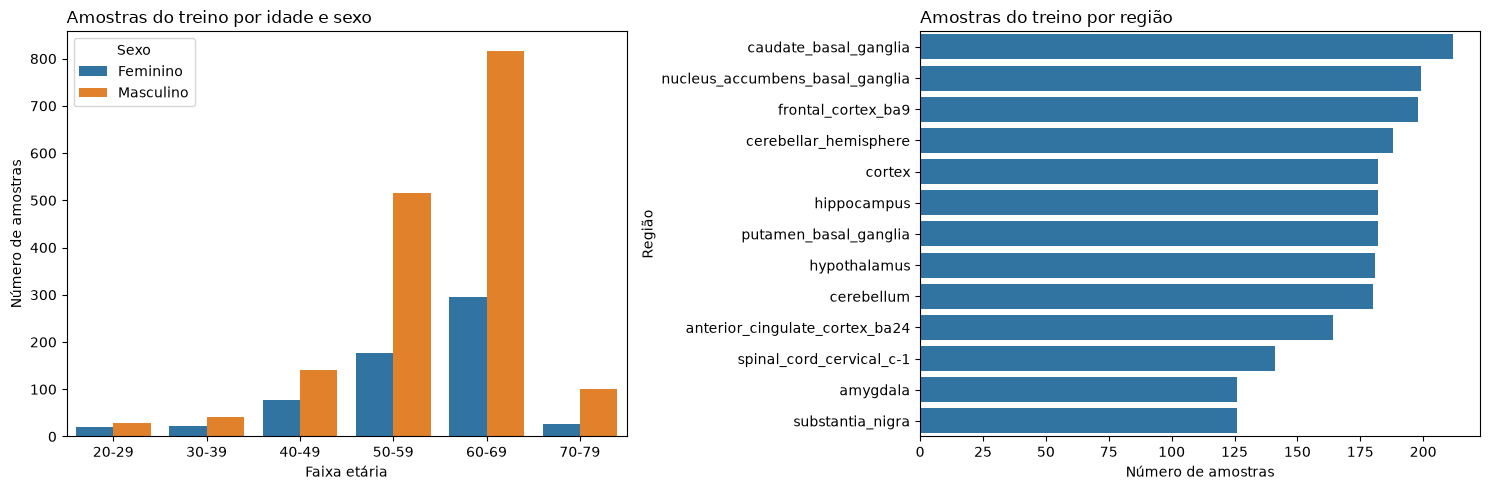

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

train_samples = samples.loc[expression.index[train]]
print("Amostras x genes no treino:", expression[train].shape)
sex_labels = {1: "Masculino", 2: "Feminino"}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.countplot(x=train_samples["AGE"], hue=train_samples["SEX"].map(sex_labels), hue_order=["Feminino", "Masculino"], order=age_order, ax=axes[0])
axes[0].set(xlabel="Faixa etária", ylabel="Número de amostras")
axes[0].set_title("Amostras do treino por idade e sexo", loc="left")
axes[0].legend(title="Sexo")

sns.countplot(y=train_samples["region"], order=train_samples["region"].value_counts().index, ax=axes[1])
axes[1].set(xlabel="Número de amostras", ylabel="Região")
axes[1].set_title("Amostras do treino por região", loc="left")

plt.tight_layout()
plt.show()

## Justificativa do undersampling aleatório

Antes de reduzir as faixas 50-59 e 60-69, verificamos se as amostras dessas faixas formam grupos que um undersampling aleatório poderia desequilibrar. Os genes das amostras de treino dessas duas faixas são padronizados (`StandardScaler`) e projetados em 2 dimensões com PCA:

- à esquerda, com os dados originais, coloridos por região;
- no centro e à direita, depois de subtrair a média de cada região (para retirar o efeito da região), coloridos por faixa etária e por sexo.

In [ ]:
majority_samples = train_samples[train_samples["AGE"].isin(Config.MAJORITY_AGES)]
scaled = StandardScaler().fit_transform(expression.loc[majority_samples.index])
region_means = pd.DataFrame(scaled).groupby(majority_samples["region"].to_numpy()).transform("mean").to_numpy()
centered = scaled - region_means

raw_pca = PCA(n_components=2, random_state=Config.RANDOM_STATE).fit(scaled)
centered_pca = PCA(n_components=2, random_state=Config.RANDOM_STATE).fit(centered)
panels = [
    (raw_pca.transform(scaled), raw_pca, majority_samples["region"], "Região", "Por região"),
    (centered_pca.transform(centered), centered_pca, majority_samples["AGE"], "Faixa etária", "Sem o efeito da região, por faixa etária"),
    (centered_pca.transform(centered), centered_pca, majority_samples["SEX"].map(sex_labels), "Sexo", "Sem o efeito da região, por sexo"),
]

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, (points, pca, hue, legend_title, title) in zip(axes, panels):
    explained = pca.explained_variance_ratio_ * 100
    sns.scatterplot(x=points[:, 0], y=points[:, 1], hue=hue.to_numpy(), s=10, alpha=0.6, ax=ax)
    ax.set(xlabel=f"PC1 ({explained[0]:.1f}%)", ylabel=f"PC2 ({explained[1]:.1f}%)")
    ax.set_title(title, loc="left")
    ax.legend(title=legend_title, fontsize=7 if legend_title == "Região" else 9, markerscale=1.5)
fig.suptitle(f"PCA das amostras de treino de {' e '.join(Config.MAJORITY_AGES)}", x=0.02, ha="left")
plt.tight_layout()
plt.show()

Aqui vemos que não tem relação direta entre os grupos de sexos de treinos para as idades nem para as regiões anatomicas, por isso vamos fazer um undersampling aleatório

## Undersampling das faixas 50-59 e 60-69 (só no treino)

A diferença entre cada faixa majoritária e a faixa de referência (40-49, a maior entre as demais) é reduzida pela metade removendo apenas amostras do sexo masculino, com o `RandomUnderSampler`, a técnica de undersampling aleatório da aula da semana 13. As amostras femininas, as outras faixas, a validação e o teste não mudam.

Antes                   Depois                
SEX   Feminino Masculino Total Feminino Masculino Total
AGE                                                    
20-29       20        29    49       20        29    49
30-39       22        41    63       22        41    63
40-49       78       140   218       78       140   218
50-59      176       516   692      176       279   455
60-69      296       817  1113      296       370   666
70-79       26       100   126       26       100   126
Total      618      1643  2261      618       959  1577

Doadores no treino antes e depois: 274 269


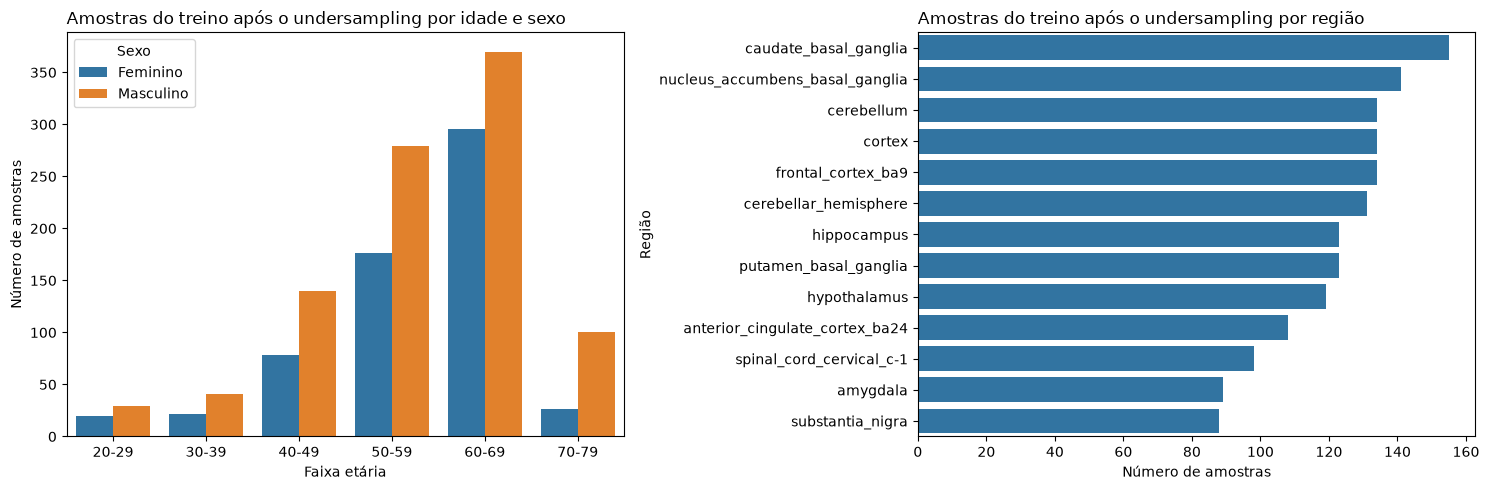

In [13]:
from imblearn.under_sampling import RandomUnderSampler

age_counts = train_samples["AGE"].value_counts()
reference = age_counts[Config.UNDERSAMPLING_REFERENCE_AGE]
age_sex = train_samples["AGE"] + "_" + train_samples["SEX"].astype(str)
age_sex_counts = age_sex.value_counts()

targets = {}
for age in Config.MAJORITY_AGES:
    age_target = int(round(age_counts[age] - (age_counts[age] - reference) * Config.GAP_REDUCTION))
    targets[f"{age}_1"] = age_target - age_sex_counts[f"{age}_2"]

sampler = RandomUnderSampler(sampling_strategy=targets, random_state=Config.RANDOM_STATE)
sampler.fit_resample(train_samples[["SEX"]], age_sex)
train_index = train_samples.index[sampler.sample_indices_]

X_train = expression.loc[train_index]
y_train = samples.loc[train_index, "AGE_ORD"]

balanced_samples = samples.loc[train_index]
display(pd.concat({
    "Antes": pd.crosstab(train_samples["AGE"], train_samples["SEX"].map(sex_labels), margins=True, margins_name="Total"),
    "Depois": pd.crosstab(balanced_samples["AGE"], balanced_samples["SEX"].map(sex_labels), margins=True, margins_name="Total"),
}, axis=1))
print("Doadores no treino antes e depois:", train_samples["SUBJID"].nunique(), balanced_samples["SUBJID"].nunique())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.countplot(x=balanced_samples["AGE"], hue=balanced_samples["SEX"].map(sex_labels), hue_order=["Feminino", "Masculino"], order=age_order, ax=axes[0])
axes[0].set(xlabel="Faixa etária", ylabel="Número de amostras")
axes[0].set_title("Amostras do treino após o undersampling por idade e sexo", loc="left")
axes[0].legend(title="Sexo")

sns.countplot(y=balanced_samples["region"], order=balanced_samples["region"].value_counts().index, ax=axes[1])
axes[1].set(xlabel="Número de amostras", ylabel="Região")
axes[1].set_title("Amostras do treino após o undersampling por região", loc="left")

plt.tight_layout()
plt.show()

## Oversampling das faixas 20-29 e 30-39 e das mulheres de 70-79 com variação (só no treino)

As faixas 20-29 e 30-39 e as amostras femininas de 70-79 passam a ter `OVERSAMPLING_FACTOR` vezes o número de amostras. As amostras novas são cópias das originais com uma variação: a cada gene é somado um ruído gaussiano com desvio padrão igual a `JITTER_SCALE` vezes o desvio padrão daquele gene no treino. As cópias são distribuídas de forma igual entre as amostras originais; quando a divisão não é exata, as cópias que sobram vão para amostras sorteadas. Valores negativos são cortados em zero, já que log2(TPM + 1) não pode ser negativo. As outras faixas, a validação e o teste não mudam.

In [14]:
rng = np.random.default_rng(Config.RANDOM_STATE)
X_balanced = expression.loc[train_index]
gene_std = X_balanced.std().to_numpy()

synthetic_parts = []
for group in Config.OVERSAMPLING_GROUPS:
    in_group = pd.concat([balanced_samples[column] == value for column, value in group.items()], axis=1).all(axis=1)
    originals = balanced_samples.index[in_group]
    n_new = int(round(len(originals) * Config.OVERSAMPLING_FACTOR)) - len(originals)
    full_rounds, extra = divmod(n_new, len(originals))
    sources = list(originals) * full_rounds + list(rng.choice(originals, size=extra, replace=False))
    noise = rng.normal(0, gene_std * Config.JITTER_SCALE, size=(len(sources), len(gene_std)))
    values = np.clip(expression.loc[sources].to_numpy() + noise, 0, None).astype("float32")
    new_index = [f"{source}_synthetic_{i}" for i, source in enumerate(sources)]
    synthetic_parts.append((pd.DataFrame(values, index=new_index, columns=expression.columns),
                            samples.loc[sources].set_axis(new_index)))

X_synthetic = pd.concat([part[0] for part in synthetic_parts])
synthetic_samples = pd.concat([part[1] for part in synthetic_parts])

X_train = pd.concat([X_balanced, X_synthetic])
oversampled_samples = pd.concat([balanced_samples.assign(origem="Original"), synthetic_samples.assign(origem="Sintética")])
y_train = oversampled_samples["AGE_ORD"]

display(pd.concat({
    "Antes": pd.crosstab(balanced_samples["AGE"], balanced_samples["SEX"].map(sex_labels), margins=True, margins_name="Total"),
    "Depois": pd.crosstab(oversampled_samples["AGE"], oversampled_samples["SEX"].map(sex_labels), margins=True, margins_name="Total"),
}, axis=1))
print("Amostras x genes no treino final:", X_train.shape)

Antes                   Depois                
SEX   Feminino Masculino Total Feminino Masculino Total
AGE                                                    
20-29       20        29    49       60        87   147
30-39       22        41    63       66       123   189
40-49       78       140   218       78       140   218
50-59      176       279   455      176       279   455
60-69      296       370   666      296       370   666
70-79       26       100   126       78       100   178
Total      618       959  1577      754      1099  1853

Amostras x genes no treino final: (1853, 17500)


### Distribuição do treino após o oversampling

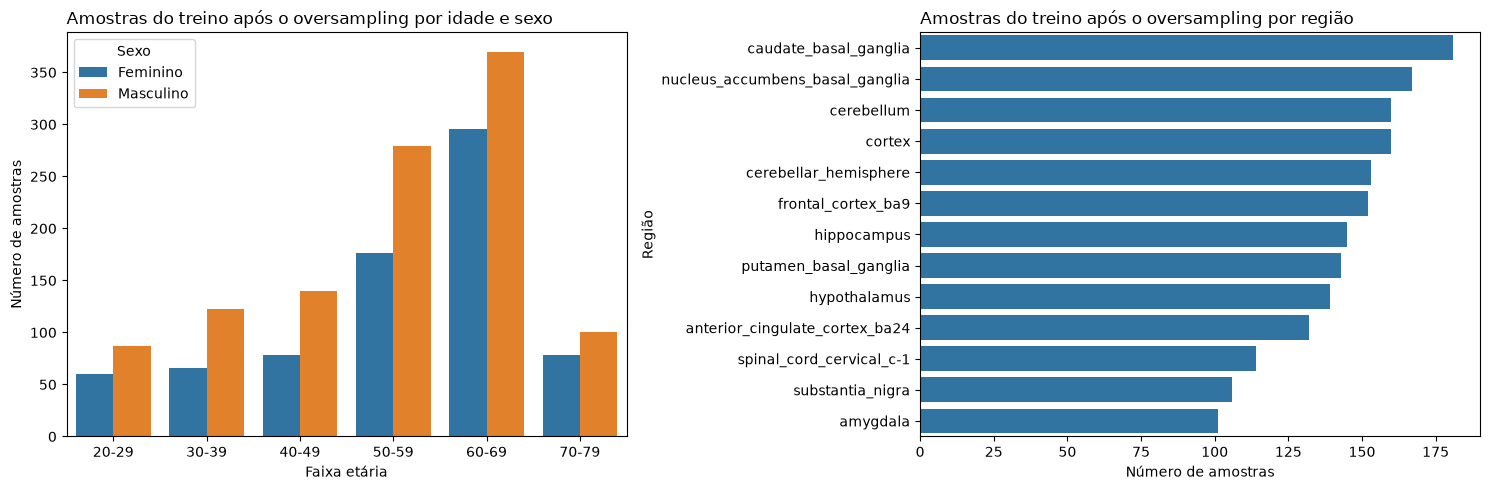

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.countplot(x=oversampled_samples["AGE"], hue=oversampled_samples["SEX"].map(sex_labels), hue_order=["Feminino", "Masculino"], order=age_order, ax=axes[0])
axes[0].set(xlabel="Faixa etária", ylabel="Número de amostras")
axes[0].set_title("Amostras do treino após o oversampling por idade e sexo", loc="left")
axes[0].legend(title="Sexo")

sns.countplot(y=oversampled_samples["region"], order=oversampled_samples["region"].value_counts().index, ax=axes[1])
axes[1].set(xlabel="Número de amostras", ylabel="Região")
axes[1].set_title("Amostras do treino após o oversampling por região", loc="left")

plt.tight_layout()
plt.show()

## Salvar os conjuntos de treino, validação e teste

In [17]:
info_columns = ["SUBJID", "region", "SEX", "AGE", "AGE_ORD", "DTHHRDY"]

save_split("train", X_train, y_train, oversampled_samples[info_columns + ["origem"]])
for name in ["val", "test"]:
    index = samples.index[samples["split"] == name]
    save_split(name, expression.loc[index], samples.loc[index, "AGE_ORD"], samples.loc[index, info_columns].assign(origem="Original"))

pd.DataFrame({
    name: [len(index), expression.shape[1]]
    for name, index in {
        "train": X_train.index,
        "val": samples.index[samples["split"] == "val"],
        "test": samples.index[samples["split"] == "test"],
    }.items()
}, index=["Amostras", "Genes"])

,train,val,test
Amostras,1853,658,315
Genes,17500,17500,17500
